In [24]:
import numpy as np
import matplotlib.pyplot as plt

# Grid
Nx = 51
Nz = 51

x = np.linspace(0, 1, Nx)
z = np.linspace(0, 1, Nz)

dx = x[1] - x[0]
dz = z[1] - z[0]

X, Z = np.meshgrid(x, z)

# Thermal diffusivity
kappa = 1.0

# Time step
dt = 0.0001

# Number of time steps
nt = 5000

# Initial temperature
T = np.zeros((Nz, Nx))

# Boundary conditions
T[0, :] = 1.0      # hot bottom
T[-1, :] = 0.0     # cold top

# Insulated left and right boundaries
T[1:-1, 0] = T[1:-1, 1]
T[1:-1, -1] = T[1:-1, -2]
print(T)

[[1. 1. 1. ... 1. 1. 1.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 ...
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]
 [0. 0. 0. ... 0. 0. 0.]]


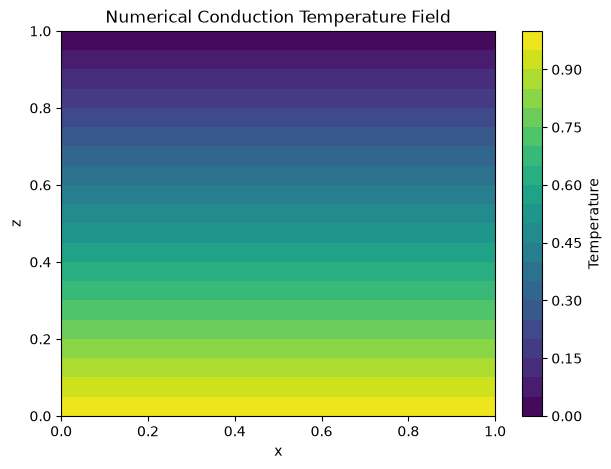

[[1.         1.         1.         ... 1.         1.         1.        ]
 [0.97999794 0.97999794 0.97999794 ... 0.97999794 0.97999794 0.97999794]
 [0.95999591 0.95999591 0.95999591 ... 0.95999591 0.95999591 0.95999591]
 ...
 [0.03999591 0.03999591 0.03999591 ... 0.03999591 0.03999591 0.03999591]
 [0.01999794 0.01999794 0.01999794 ... 0.01999794 0.01999794 0.01999794]
 [0.         0.         0.         ... 0.         0.         0.        ]]


In [83]:
import numpy as np
import matplotlib.pyplot as plt

# -----------------------------
# Grid
# -----------------------------

Nx = 51
Nz = 51

x = np.linspace(0, 1, Nx)
z = np.linspace(0, 1, Nz)

dx = x[1] - x[0]
dz = z[1] - z[0]

X, Z = np.meshgrid(x, z)

# -----------------------------
# Physical parameter
# -----------------------------

kappa = 1

# -----------------------------
# Time parameters
# -----------------------------

dt = 0.0002
nt = 5000

# -----------------------------
# Initial temperature
# -----------------------------

T = np.zeros((Nz, Nx))

# Boundary conditions
T[0, :] = 1.0
T[-1, :] = 0.0

# -----------------------------
# Time stepping
# -----------------------------

for n in range(nt):

    d2Tdx2 = (
        T[1:-1, 2:]
        - 2*T[1:-1, 1:-1]
        + T[1:-1, :-2]
    ) / dx**2

    d2Tdz2 = (
        T[2:, 1:-1]
        - 2*T[1:-1, 1:-1]
        + T[:-2, 1:-1]
    ) / dz**2

    T[1:-1, 1:-1] += dt * kappa * (
        d2Tdx2 + d2Tdz2
    )
    # Insulated side boundaries
    T[1:-1, 0] = T[1:-1, 1]
    T[1:-1, -1] = T[1:-1, -2]

    # Fixed temperature boundaries
    T[0, :] = 1.0
    T[-1, :] = 0.0

# -----------------------------
# Plot final temperature field
# -----------------------------

plt.figure(figsize=(7, 5))

contour = plt.contourf(
    X, Z, T, levels=20
)

plt.colorbar(
    contour,
    label="Temperature"
)

plt.xlabel("x")
plt.ylabel("z")

plt.title("Numerical Conduction Temperature Field")

plt.show()
print(T)

In [74]:
T_analytical = 1 - Z

In [75]:
error = np.abs(T - T_analytical)

print("Maximum error:", np.max(error))

Maximum error: 0.004583308894041294


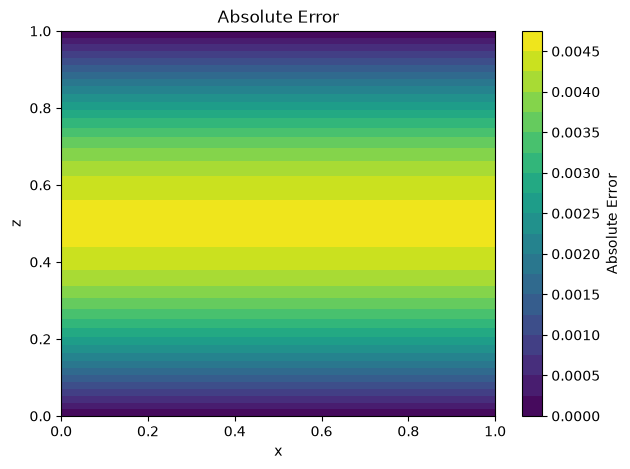

In [76]:
plt.figure(figsize=(7,5))

plt.contourf(X, Z, error, levels=20)

plt.xlabel("x")
plt.ylabel("z")
plt.title("Absolute Error")

plt.colorbar(label="Absolute Error")

plt.show()

In [77]:
mid_x = Nx // 2

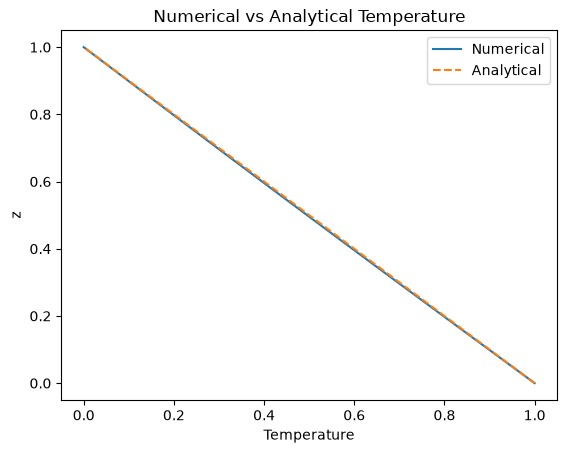

In [50]:
plt.plot(T[:,mid_x], z, label="Numerical")
plt.plot(1-z, z, "--", label="Analytical")

plt.xlabel("Temperature")
plt.ylabel("z")
plt.legend()
plt.title("Numerical vs Analytical Temperature")
plt.show()

Running 31 x 31 grid...
Grid: 31 x 31, dx = 0.03333, dt = 5.56e-05, iterations = 10684, max error = 1.823664e-03, RMS error = 1.268556e-03
Running 51 x 51 grid...
Grid: 51 x 51, dx = 0.02000, dt = 2.00e-05, iterations = 24491, max error = 5.066383e-03, RMS error = 3.547178e-03
Running 101 x 101 grid...
Grid: 101 x 101, dx = 0.01000, dt = 5.00e-06, iterations = 69859, max error = 2.026480e-02, RMS error = 1.425826e-02

-----------------------------------------------
GRID CONVERGENCE RESULTS
-----------------------------------------------
Grid        dx          dt             Iterations     Max Error      RMS Error
-----------------------------------------------
31 x 31     0.03333     5.56e-05       10684          1.823664e-03   1.268556e-03
51 x 51     0.02000     2.00e-05       24491          5.066383e-03   3.547178e-03
101 x 101    0.01000     5.00e-06       69859          2.026480e-02   1.425826e-02


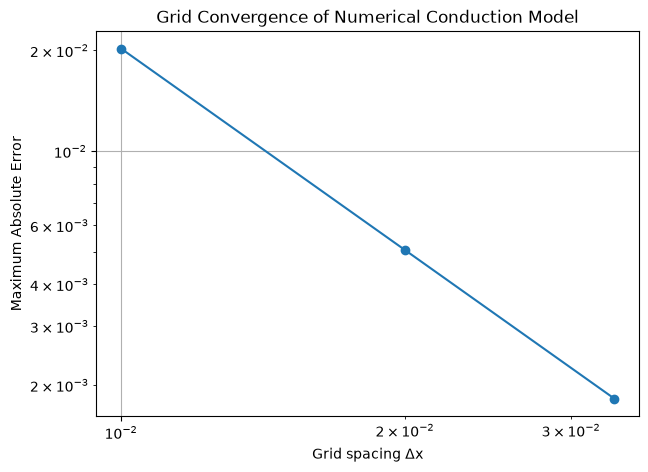

In [41]:
import numpy as np
import matplotlib.pyplot as plt


# --------------------------------------------------
# Physical parameters
# --------------------------------------------------

kappa = 1.0

# Grid sizes to test
grid_sizes = [31, 51, 101]

# Convergence criterion
tolerance = 1e-6

# Safety factor for numerical stability
# Explicit 2-D scheme requires:
# dt <= dx^2 / (4*kappa)
safety_factor = 0.2


# --------------------------------------------------
# Function to run the numerical conduction model
# --------------------------------------------------

def run_conduction(N):

    # ----------------------------------------------
    # 1. Create grid
    # ----------------------------------------------

    Nx = N
    Nz = N

    x = np.linspace(0, 1, Nx)
    z = np.linspace(0, 1, Nz)

    dx = x[1] - x[0]
    dz = z[1] - z[0]

    X, Z = np.meshgrid(x, z)


    # ----------------------------------------------
    # 2. Choose stable time step
    # ----------------------------------------------

    dt_max = 1 / (
        2 * kappa *
        (1/dx**2 + 1/dz**2)
    )

    dt = safety_factor * dt_max


    # ----------------------------------------------
    # 3. Initial temperature
    # ----------------------------------------------

    T = np.zeros((Nz, Nx))

    # Bottom boundary: hot
    T[0, :] = 1.0

    # Top boundary: cold
    T[-1, :] = 0.0


    # ----------------------------------------------
    # 4. Time stepping
    # ----------------------------------------------

    max_iterations = 200000

    for n in range(max_iterations):

        # Create a copy of the current temperature
        T_new = T.copy()


        # ------------------------------------------
        # Second derivative in x
        # ------------------------------------------

        d2Tdx2 = (
            T[1:-1, 2:]
            - 2*T[1:-1, 1:-1]
            + T[1:-1, :-2]
        ) / dx**2


        # ------------------------------------------
        # Second derivative in z
        # ------------------------------------------

        d2Tdz2 = (
            T[2:, 1:-1]
            - 2*T[1:-1, 1:-1]
            + T[:-2, 1:-1]
        ) / dz**2


        # ------------------------------------------
        # Explicit heat equation update
        # ------------------------------------------

        T_new[1:-1, 1:-1] = (
            T[1:-1, 1:-1]
            + dt * kappa *
            (d2Tdx2 + d2Tdz2)
        )


        # ------------------------------------------
        # Insulated left boundary
        # dT/dx = 0
        # ------------------------------------------

        T_new[1:-1, 0] = T_new[1:-1, 1]


        # ------------------------------------------
        # Insulated right boundary
        # dT/dx = 0
        # ------------------------------------------

        T_new[1:-1, -1] = T_new[1:-1, -2]


        # ------------------------------------------
        # Fixed temperature boundaries
        # ------------------------------------------

        T_new[0, :] = 1.0
        T_new[-1, :] = 0.0


        # ------------------------------------------
        # Check convergence
        # ------------------------------------------

        change = np.max(np.abs(T_new - T))

        T = T_new

        if change < tolerance:
            break


    # ------------------------------------------------
    # 5. Analytical solution
    # ------------------------------------------------

    T_analytical = 1 - Z


    # ------------------------------------------------
    # 6. Calculate errors
    # ------------------------------------------------

    absolute_error = np.abs(T - T_analytical)

    max_error = np.max(absolute_error)

    rms_error = np.sqrt(
        np.mean((T - T_analytical)**2)
    )


    # ------------------------------------------------
    # 7. Return results
    # ------------------------------------------------

    return {
        "N": N,
        "dx": dx,
        "dt": dt,
        "iterations": n + 1,
        "max_error": max_error,
        "rms_error": rms_error,
        "T": T,
        "X": X,
        "Z": Z
    }


# ==================================================
# Run all grid sizes
# ==================================================

results = []

for N in grid_sizes:

    print(f"Running {N} x {N} grid...")

    result = run_conduction(N)

    results.append(result)

    print(
        f"Grid: {N} x {N}, "
        f"dx = {result['dx']:.5f}, "
        f"dt = {result['dt']:.2e}, "
        f"iterations = {result['iterations']}, "
        f"max error = {result['max_error']:.6e}, "
        f"RMS error = {result['rms_error']:.6e}"
    )


# ==================================================
# Create results table
# ==================================================

print("\n-----------------------------------------------")
print("GRID CONVERGENCE RESULTS")
print("-----------------------------------------------")

print(
    f"{'Grid':<12}"
    f"{'dx':<12}"
    f"{'dt':<15}"
    f"{'Iterations':<15}"
    f"{'Max Error':<15}"
    f"{'RMS Error'}"
)

print("-----------------------------------------------")

for r in results:

    print(
        f"{r['N']} x {r['N']:<7}"
        f"{r['dx']:<12.5f}"
        f"{r['dt']:<15.2e}"
        f"{r['iterations']:<15}"
        f"{r['max_error']:<15.6e}"
        f"{r['rms_error']:.6e}"
    )


# ==================================================
# Plot maximum error vs grid spacing
# ==================================================

dx_values = [r["dx"] for r in results]
max_errors = [r["max_error"] for r in results]

plt.figure(figsize=(7, 5))

plt.loglog(
    dx_values,
    max_errors,
    "o-"
)

plt.xlabel("Grid spacing Δx")
plt.ylabel("Maximum Absolute Error")
plt.title("Grid Convergence of Numerical Conduction Model")

plt.grid(True)

plt.show()

 31 x 31  | dx = 0.03333 | dt = 5.56e-05 | Iterations =  26622 | Time = 1.4790 | Residual = 1.00e-08 | Max Error = 1.014e-09 | RMS Error = 7.052e-10
 51 x 51  | dx = 0.02000 | dt = 2.00e-05 | Iterations =  71264 | Time = 1.4253 | Residual = 1.00e-08 | Max Error = 1.014e-09 | RMS Error = 7.096e-10
101 x 101 | dx = 0.01000 | dt = 5.00e-06 | Iterations = 270763 | Time = 1.3538 | Residual = 1.00e-08 | Max Error = 1.013e-09 | RMS Error = 7.130e-10


GRID CONVERGENCE RESULTS
---------------------------------------------------------------------------
Grid        dx          dt            Iterations    Max Error      RMS Error      
---------------------------------------------------------------------------
31 x 31      0.03333     5.56e-05      26622         1.013723e-09   7.051540e-10   
51 x 51      0.02000     2.00e-05      71264         1.013518e-09   7.096051e-10   
101 x 101     0.01000     5.00e-06      270763        1.013370e-09   7.130078e-10   


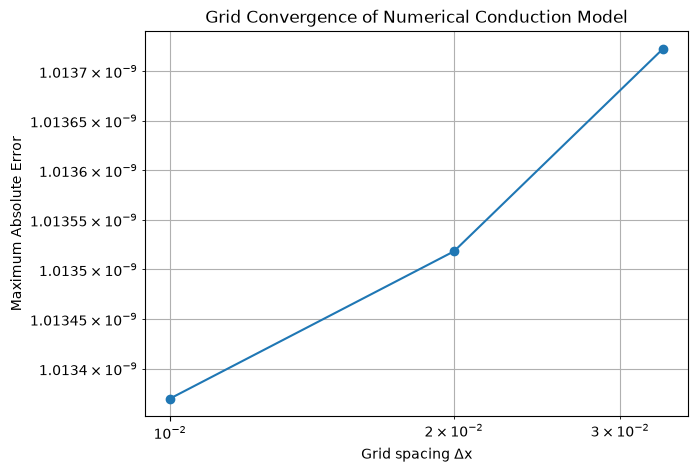

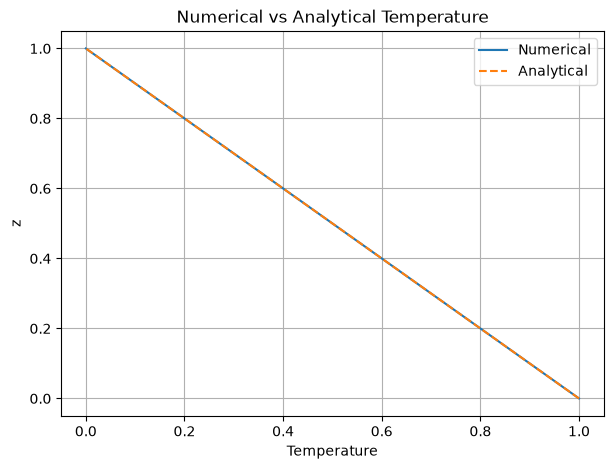

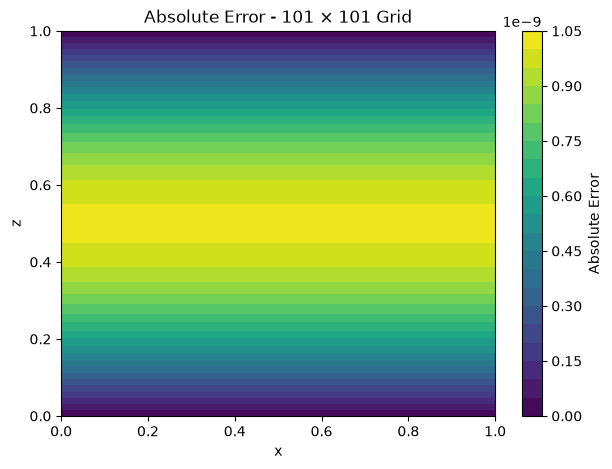

In [2]:
import numpy as np
import matplotlib.pyplot as plt


# ============================================================
# 2-D NUMERICAL CONDUCTION - GRID CONVERGENCE TEST
# ============================================================

# Physical parameters
kappa = 1.0

# Grid sizes to test
grid_sizes = [31, 51, 101]

# Convergence criterion
residual_tolerance = 1e-8

# Safety factor for stable time step
safety_factor = 0.2


# ------------------------------------------------------------
# Function to solve the conduction equation
# ------------------------------------------------------------

def solve_conduction(N):

    # Domain: 0 <= x <= 1, 0 <= z <= 1
    Lx = 1.0
    Lz = 1.0

    dx = Lx / (N - 1)
    dz = Lz / (N - 1)

    # Stable timestep
    dt_max = 1.0 / (
        2 * kappa *
        (1 / dx**2 + 1 / dz**2)
    )

    dt = safety_factor * dt_max

    # --------------------------------------------------------
    # Initial temperature
    # --------------------------------------------------------

    # Array arrangement:
    # T[z, x]

    T = np.zeros((N, N))

    # Initial interior temperature
    T[1:-1, 1:-1] = 0.5

    # Boundary conditions
    # Bottom = hot
    T[0, :] = 1.0

    # Top = cold
    T[-1, :] = 0.0

    # --------------------------------------------------------
    # Time stepping
    # --------------------------------------------------------

    max_iterations = 500000

    for iteration in range(max_iterations):

        T_new = T.copy()

        # Interior points
        T_new[1:-1, 1:-1] = (
            T[1:-1, 1:-1]
            + kappa * dt * (
                (T[1:-1, 2:] - 2*T[1:-1, 1:-1]
                 + T[1:-1, :-2]) / dx**2
                +
                (T[2:, 1:-1] - 2*T[1:-1, 1:-1]
                 + T[:-2, 1:-1]) / dz**2
            )
        )

        # ----------------------------------------------------
        # Insulated side boundaries
        # dT/dx = 0
        # ----------------------------------------------------

        T_new[1:-1, 0] = T_new[1:-1, 1]
        T_new[1:-1, -1] = T_new[1:-1, -2]

        # ----------------------------------------------------
        # Fixed top and bottom temperatures
        # ----------------------------------------------------

        T_new[0, :] = 1.0
        T_new[-1, :] = 0.0

        # ----------------------------------------------------
        # Calculate steady-state residual
        #
        # At steady state:
        #
        #       ∇²T = 0
        # ----------------------------------------------------

        laplacian = (
            (T_new[1:-1, 2:] - 2*T_new[1:-1, 1:-1]
             + T_new[1:-1, :-2]) / dx**2
            +
            (T_new[2:, 1:-1] - 2*T_new[1:-1, 1:-1]
             + T_new[:-2, 1:-1]) / dz**2
        )

        residual = np.max(np.abs(laplacian))

        # Update temperature
        T = T_new

        # Check convergence
        if residual < residual_tolerance:
            break

    # --------------------------------------------------------
    # Analytical solution
    #
    # T(z) = 1 - z
    # --------------------------------------------------------

    z = np.linspace(0, 1, N)
    x = np.linspace(0, 1, N)

    X, Z = np.meshgrid(x, z)

    T_analytical = 1 - Z

    # --------------------------------------------------------
    # Error calculation
    # --------------------------------------------------------

    absolute_error = np.abs(T - T_analytical)

    max_error = np.max(absolute_error)

    rms_error = np.sqrt(
        np.mean(absolute_error**2)
    )

    # Physical time reached
    total_time = (iteration + 1) * dt

    return (
        dx,
        dz,
        dt,
        iteration + 1,
        total_time,
        residual,
        max_error,
        rms_error,
        T,
        T_analytical,
        x,
        z
    )


# ============================================================
# RUN ALL GRID SIZES
# ============================================================

results = []

for N in grid_sizes:

    result = solve_conduction(N)

    (
        dx,
        dz,
        dt,
        iterations,
        total_time,
        residual,
        max_error,
        rms_error,
        T,
        T_analytical,
        x,
        z
    ) = result

    results.append(result)

    print(
        f"{N:3d} x {N:<3d} | "
        f"dx = {dx:.5f} | "
        f"dt = {dt:.2e} | "
        f"Iterations = {iterations:6d} | "
        f"Time = {total_time:.4f} | "
        f"Residual = {residual:.2e} | "
        f"Max Error = {max_error:.3e} | "
        f"RMS Error = {rms_error:.3e}"
    )


# ============================================================
# GRID CONVERGENCE TABLE
# ============================================================

print("\n")
print("GRID CONVERGENCE RESULTS")
print("-" * 75)

print(
    f"{'Grid':<12}"
    f"{'dx':<12}"
    f"{'dt':<14}"
    f"{'Iterations':<14}"
    f"{'Max Error':<15}"
    f"{'RMS Error':<15}"
)

print("-" * 75)

for N, result in zip(grid_sizes, results):

    (
        dx,
        dz,
        dt,
        iterations,
        total_time,
        residual,
        max_error,
        rms_error,
        T,
        T_analytical,
        x,
        z
    ) = result

    print(
        f"{N} x {N:<8}"
        f"{dx:<12.5f}"
        f"{dt:<14.2e}"
        f"{iterations:<14}"
        f"{max_error:<15.6e}"
        f"{rms_error:<15.6e}"
    )


# ============================================================
# PLOT 1: MAXIMUM ERROR VS GRID SPACING
# ============================================================

dx_values = []
max_errors = []

for result in results:

    dx = result[0]
    max_error = result[6]

    dx_values.append(dx)
    max_errors.append(max_error)


plt.figure(figsize=(7, 5))

plt.loglog(
    dx_values,
    max_errors,
    'o-'
)

plt.xlabel("Grid spacing Δx")
plt.ylabel("Maximum Absolute Error")

plt.title(
    "Grid Convergence of Numerical Conduction Model"
)

plt.grid(True, which="both")

plt.show()


# ============================================================
# PLOT 2: NUMERICAL VS ANALYTICAL SOLUTION
# ============================================================

# Get the finest-grid result (101 x 101)
(
    dx,
    dz,
    dt,
    iterations,
    total_time,
    residual,
    max_error,
    rms_error,
    T,
    T_analytical,
    x,
    z
) = results[-1]

# Middle vertical column
mid_x = len(x) // 2

plt.figure(figsize=(7, 5))

plt.plot(
    T[:, mid_x],
    z,
    label="Numerical"
)

plt.plot(
    1 - z,
    z,
    '--',
    label="Analytical"
)

plt.xlabel("Temperature")
plt.ylabel("z")

plt.title("Numerical vs Analytical Temperature")

plt.legend()
plt.grid(True)

plt.show()


# ============================================================
# PLOT 3: ABSOLUTE ERROR - 101 x 101
# ============================================================

absolute_error = np.abs(T - T_analytical)

plt.figure(figsize=(7, 5))

plt.contourf(
    x,
    z,
    absolute_error,
    levels=20
)

plt.colorbar(label="Absolute Error")

plt.xlabel("x")
plt.ylabel("z")

plt.title("Absolute Error - 101 × 101 Grid")

plt.show()